# NLP end-to-end and embeddings

This notebook presents the complete pipeline and its recorded results. Reusable implementations live in `src/`; displayed source establishes the training and evaluation methods. Markdown cells explain decisions. The default execution reuses checkpoints and does not reopen final test.

In [1]:
from pathlib import Path
import sys, inspect
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image, Markdown, HTML
from src.common import ARTIFACTS, RESULTS, FIGURES, load_json
from src.deliverables import embedding_rows, iteration_rows, category_rows, validation_rows
from src.preprocessing import tokenize, sentences, keep_probabilities, pair_batches, prepare
from src.sgns import SGNS, CONFIGURATIONS, train_configuration, pilot
from src.experiments import train_embeddings, arithmetic
from src.evaluation import analogia, analogy_benchmark, parallelism
from src.classification import BagClassifier, classification, final_evaluation
from src.checks import main as run_checks
pd.set_option('display.max_columns', 25)
pd.set_option('display.max_colwidth', 130)
RUN_TRAINING = False
display(pd.Series(load_json(RESULTS / 'environment.json')))

seed                                                                                                                                            23556
python                                                                                                                                        3.12.13
platform                                                                                                                    Windows-11-10.0.26200-SP0
cpu                                                                                                AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD
cpu_threads                                                                                                                                        12
packages            {'torch': '2.13.0+cu130', 'numpy': '2.5.1', 'scipy': '1.18.0', 'pandas': '3.0.5', 'matplotlib': '3.11.1', 'datasets': '5.0.1',...
cuda                                                                                                

## 2. Corpus exploration and preprocessing

Article counts use top-level title markers; body-token counts exclude headings. Token counts before vocabulary filtering and after filtering are reported separately.

In [2]:
prep = load_json(RESULTS / 'preprocessing.json')
display(pd.DataFrame(prep['splits']).T)
display(pd.DataFrame(prep['subsets']).T)

,lines,nonempty_lines,articles,tokens,fingerprint
test,4358,2891,62,204879,c30409b5a24d230f
train,1801350,1165029,29444,85929215,7dabb830ac9ebb0d
validation,3760,2461,60,182322,ea37ea707fafbf9f


,normalized_tokens,sentences,retained_tokens,encoded_end,counts
20000000,20265144.0,942732.0,20000000.0,20000000.0,NaN
30000000,30000017.0,1394201.0,29507792.0,29507792.0,NaN
40000000,40000011.0,1859954.0,39275085.0,39275085.0,NaN


### Normalization, tokens and IDs

Lowercasing matches uncased GloVe. Internal apostrophes and numeric separators are retained; punctuation is removed and hyphens split. WikiText markers are repaired. Unknown corpus words are dropped before generating contexts.

In [3]:
print(inspect.getsource(tokenize))
print(inspect.getsource(sentences))
words = load_json(ARTIFACTS / 'vocabulary.json')
word_to_id = {word: i for i, word in enumerate(words)}
example = tokenize("The king's well-known computer costs 1 @,@ 000.")
display(pd.DataFrame({'token': example, 'id': [word_to_id.get(word, -1) for word in example]}))

def tokenize(text):
    text = text.lower().replace("’", "'")
    for source, target in ((" @-@ ", "-"), (" @,@ ", ","), (" @.@ ", ".")):
        text = text.replace(source, target)
    return WORD_PATTERN.findall(text)

def sentences(text):
    if not text.strip() or HEADING_PATTERN.match(text):
        return []
    return [tokens for part in SENTENCE_PATTERN.split(text) if (tokens := tokenize(part))]



,token,id
0,the,0
1,king's,-1
2,well,104
3,known,121
4,computer,1660
5,costs,2683
6,"1,000",2197


In [4]:
display(pd.DataFrame(prep['tokenizers']))

,text,custom,nltk
0,I can't believe it's already January.,"[i, can't, believe, it's, already, january]","[i, ca, n't, believe, it, 's, already, january, .]"
1,They're buying state-of-the-art computers.,"[they're, buying, state, of, the, art, computers]","[they, 're, buying, state-of-the-art, computers, .]"
2,Dr. Smith lives in the U.S.A.,"[dr, smith, lives, in, the, u, s, a]","[dr., smith, lives, in, the, u.s.a, .]"
3,"The price is $12.50, not $1,250.","[the, price, is, 12.50, not, 1,250]","[the, price, is, $, 12.50, ,, not, $, 1,250, .]"
4,King's horses aren't running.,"[king's, horses, aren't, running]","[king, 's, horses, are, n't, running, .]"
5,COVID-19 changed 2020–2021.,"[covid, 19, changed, 2020, 2021]","[covid-19, changed, 2020–2021, .]"
6,Email alice@example.com or visit https://example.com.,"[email, alice, example, com, or, visit, https, example, com]","[email, alice, @, example.com, or, visit, https, :, //example.com, .]"
7,“Hello!” she said... then left.,"[hello, she, said, then, left]","[“hello, !, ”, she, said, ..., then, left, .]"
8,He'll re-enter the twenty-first competition.,"[he'll, re, enter, the, twenty, first, competition]","[he, 'll, re-enter, the, twenty-first, competition, .]"
9,New York's capital isn't New York City.,"[new, york's, capital, isn't, new, york, city]","[new, york, 's, capital, is, n't, new, york, city, .]"


### Zipf and vocabulary coverage

The log-log slope is an empirical approximation, not a proof of an exact Zipf law. Coverage uses all normalized training-body tokens; threshold comparison uses the smallest nested subset.

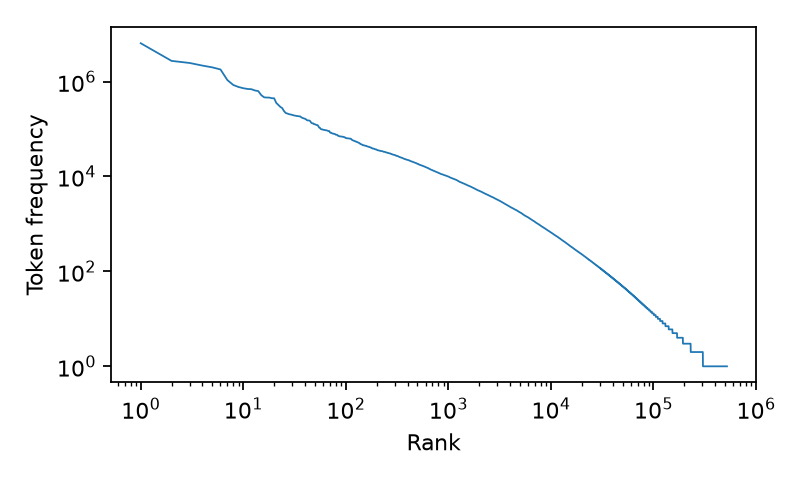

10       0.244378
1000     0.646248
30000    0.955111
Name: token_coverage, dtype: float64

Top-30000 slope: -1.2739024377754047


,min_count,vocabulary,unknown_percent
0,5,80087,1.294629
1,10,54175,2.144984
2,20,36728,3.336574


In [5]:
display(Image(filename=str(FIGURES / 'zipf.png')))
display(pd.Series(prep['coverage'], name='token_coverage'))
print('Top-30000 slope:', prep['zipf_slope_top_30000'])
display(pd.DataFrame(prep['threshold_comparison']))

### Subsampling and skip-gram pairs

The reported realized discard rates use the seed shown in environment metadata. Pair counts include both context directions and never cross sentence boundaries.

In [6]:
print(inspect.getsource(keep_probabilities))
print(inspect.getsource(pair_batches))
display(pd.DataFrame(prep['subsampling']).T)
display(pd.Series({key: prep[key] for key in ('pairs_before_subsampling', 'pairs_after_subsampling', 'retained_after_subsampling')}))

def keep_probabilities(counts, sample=SAMPLE):
    counts = np.asarray(counts, dtype=np.float64)
    if sample <= 0:
        return np.ones_like(counts)
    frequencies = counts / counts.sum()
    return np.minimum(1.0, (np.sqrt(frequencies / sample) + 1) * sample / frequencies)

def pair_batches(ids, sentence_ids, window, batch_size=2048, chunk_size=65536, seed=SEED):
    rng = np.random.default_rng(seed)
    for start in range(0, len(ids), chunk_size):
        positions = np.arange(start, min(start + chunk_size, len(ids)))
        centers, contexts = [], []
        for offset in range(-window, window + 1):
            if offset == 0:
                continue
            neighbors = positions + offset
            valid = (neighbors >= 0) & (neighbors < len(ids))
            left, right = positions[valid], neighbors[valid]
            valid = sentence_ids[left] == sentence_ids[right]
            centers.append(ids[left[valid]])
            contexts.append(ids[right[valid]])
        cen

,theoretical_discard_percent,observed_discard_percent
the,96.240931,96.264229
of,94.137420,94.129031
and,93.813239,93.796066


pairs_before_subsampling      337969464
pairs_after_subsampling       180580964
retained_after_subsampling     23472408
dtype: int64

# Embeddings: API research and methodological decisions

## PyTorch tools

`nn.Embedding(num_embeddings, embedding_dim)` stores one trainable row per token
ID. `padding_idx` fixes a reserved row and prevents its gradient updates.
`sparse=True` produces sparse gradients, useful for large vocabularies, but
requires a compatible optimizer such as SGD or SparseAdam. Two independent
tables represent SGNS input words and output contexts.

`nn.Embedding.from_pretrained(weights, freeze=True)` initializes a table from an
existing two-dimensional tensor. `freeze=False` enables fine-tuning. The
pretrained dimension and row-to-token mapping must be preserved.

`nn.EmbeddingBag` aggregates variable-length sequences without constructing the
full intermediate embedding tensor. `mode="mean"` averages nonpadding rows,
`"sum"` adds them, and `"max"` takes componentwise maxima. `offsets` identifies
where each document begins in a flattened ID array. With
`include_last_offset=True`, a final offset gives the flattened array length.
The classifier uses mean aggregation followed by a linear layer, ReLU, dropout,
and a four-class output layer. Padding ID zero is ignored. A document containing
only unknown tokens receives a zero aggregate instead of an undefined mean.

## Gensim tools

`Word2Vec` uses `sg=1` for skip-gram, `vector_size` for the vector dimension,
`window` for the maximum context distance, `negative` for negative samples,
`sample` for subsampling, `min_count` for vocabulary filtering, `alpha` and
`min_alpha` for the learning-rate schedule, and `epochs` for corpus passes.
`ns_exponent=0.75` defines the smoothed negative distribution.
`shrink_windows=False` matches the custom fixed context window.
`build_vocab_from_freq` explicitly constructs the shared vocabulary.
`train(..., compute_loss=True)` exposes the accumulated training loss, which is
not directly interchangeable with the custom mean loss per positive pair.

`KeyedVectors` retains vectors without the training state. `add_vectors`
constructs an evaluation model, `save` and `load` persist it, and
`save_word2vec_format` exports text vectors. `most_similar` performs normalized
cosine retrieval; `similarity` compares two words. The assignment supplies
benchmarks through `gensim.test.utils.datapath`. This implementation verifies
their availability and uses explicit shared-question filtering rather than
allowing separate coverage denominators.

`gensim.downloader.load("glove-wiki-gigaword-100")` loads the original 100D
Wikipedia/Gigaword vectors. These original vectors are never modified.
Classification fine-tuning occurs in a separate PyTorch table.

## Learning objectives

CBOW predicts a central word from aggregated context. Skip-gram predicts
contexts from one central word. SGNS replaces a full-vocabulary softmax with
binary positive-versus-noise objectives:

$$
\mathcal{L} =
-\log \sigma(u_c^\top v_o)
-\sum_{j=1}^{K}\log \sigma(-u_c^\top v_{n_j}).
$$

Input vectors $u$ and output vectors $v$ have different roles. Using one table
would impose symmetry not required by the prediction task. The exported model
uses the input table; the output table remains in training checkpoints.

Word2Vec learns through local predictive examples. GloVe instead fits weighted
logarithms of global word co-occurrence counts. This comparison does not isolate
the method because the GloVe training corpus is much larger and separately
tokenized.

## Preprocessing and fair comparison

The tokenizer lowercases text, standardizes curly apostrophes, repairs
WikiText's `@-@`, `@,@`, and `@.@` markers, preserves internal apostrophes and
numeric forms, and drops stand-alone punctuation. Hyphenated compounds split
into words. Headings are excluded from body-token counts and training.
Sentence boundaries use punctuation followed by whitespace. Abbreviations can
therefore be split imperfectly, a disclosed limitation rather than an assumed
linguistically complete sentence segmenter.

Lowercasing matches the uncased GloVe vocabulary. Numeric strings are retained
rather than mapped to an artificial token absent from GloVe. Punctuation
differences and contractions are quantified through coverage and the tokenizer
comparison. AG News reuses exactly this tokenizer and normalization.

The vocabulary uses frequency at least five in the first 20-million-token
subset. It remains fixed for corpus-size and hyperparameter comparisons.
The smallest training subset extends slightly beyond 20 million normalized
tokens to retain at least 20 million tokens after vocabulary filtering.
Unknown corpus words are removed before contexts are constructed in both
training implementations. Negative draws follow retained-vocabulary counts
raised to the power of 0.75. Frequent words are independently retained with

$$
p_{\mathrm{keep}}(w)=
\min\left(1,
\left[\sqrt{f(w)/t}+1\right]t/f(w)\right).
$$

This reduces dominance by function words, decreases pair counts, and increases
the relative contribution of informative rarer words.

SGNS uses summed minibatch gradients with SGD. This preserves the per-pair
learning-rate scale but differs from gensim's sequential asynchronous updates.
Custom negative samples can coincide with the positive context; gensim skips
those collisions. Multithreaded gensim is not bitwise deterministic.

## Selection, arithmetic, and held-out evaluation

All embedding configurations are selected by 3CosAdd accuracy on one fixed
shared question set, with WordSim-353 Spearman as the tie-breaker.
SimLex-999 is not read during selection. Each benchmark reports coverage.

3CosAdd normalizes each source vector, constructs $b-a+c$, normalizes that
result, and ranks candidate cosine similarities. The three query words are
excluded unless an experiment explicitly disables exclusion.
3CosMul uses shifted cosine similarities:

$$
\operatorname{score}(x)=
\frac{[1+\cos(x,b)][1+\cos(x,c)]}
{2[1+\cos(x,a)]+\epsilon}.
$$

The implemented denominator adds $10^{-6}$ after shifting cosines to $[0,1]$.
Individual analogy ranks cover the model's entire vocabulary; systematic
benchmark ranks use the fixed 30,000-word intersection.

The absent assignment section 5.3 is operationalized as the cosine between
raw difference vectors $v_b-v_a$ and $v_d-v_c$ for independent examples of the
same relationship. Shared-word comparisons are excluded. Category counts and
the overall mean accompany the result.

Classifier selection uses only a seeded stratified training/validation split.
Training fractions are nested within each class. Each selected initialization
and training fraction is evaluated once on official test, with results cached.
The full-data selected models also receive confusion matrices.

## Sources

1. PyTorch, Embedding:
   <https://docs.pytorch.org/docs/stable/generated/torch.nn.Embedding.html>
2. PyTorch, EmbeddingBag:
   <https://docs.pytorch.org/docs/2.13/generated/torch.nn.EmbeddingBag.html>
3. Gensim, Word2Vec:
   <https://radimrehurek.com/gensim/models/word2vec.html>
4. Mikolov et al., Distributed Representations of Words and Phrases, 2013:
   <https://arxiv.org/abs/1310.4546>
5. Pennington et al., GloVe: Global Vectors for Word Representation, 2014:
   <https://nlp.stanford.edu/pubs/glove.pdf>
6. Original GloVe models, corpus and vocabulary metadata:
   <https://nlp.stanford.edu/projects/glove/>
7. Hill et al., SimLex-999:
   <https://fh295.github.io/simlex.html>
8. Levy and Goldberg, Linguistic Regularities in Sparse and Explicit Word
   Representations, 2014:
   <https://aclanthology.org/W14-1618/>


## 4. Custom SGNS and reference implementations

No gensim Word2Vec call appears inside the custom SGNS implementation. The input and output tables are distinct, negative draws follow count^0.75, and only input vectors are exported.

In [7]:
print(inspect.getsource(SGNS))
print(inspect.getsource(train_configuration))
run_checks()
display(pd.Series(load_json(RESULTS / 'pilot.json')))

class SGNS(nn.Module):
    def __init__(self, vocabulary_size, dimension):
        super().__init__()
        self.input = nn.Embedding(vocabulary_size, dimension, sparse=True)
        self.output = nn.Embedding(vocabulary_size, dimension, sparse=True)
        nn.init.uniform_(self.input.weight, -0.5 / dimension, 0.5 / dimension)
        nn.init.zeros_(self.output.weight)

    def forward(self, centers, contexts, negatives):
        source = self.input(centers)
        positive = (source * self.output(contexts)).sum(dim=-1)
        negative = torch.bmm(self.output(negatives), source.unsqueeze(-1)).squeeze(-1)
        return -F.logsigmoid(positive) - F.logsigmoid(-negative).sum(dim=-1)

    def keyed_vectors(self, words):
        from gensim.models import KeyedVectors

        vectors = KeyedVectors(vector_size=self.input.embedding_dim)
        vectors.add_vectors(words, self.input.weight.detach().cpu().numpy())
        return vectors

def train_configuration(config, glove):
    seed_al

Preprocessing, SGNS, analogy, EmbeddingBag, and split checks passed.


device                                 cuda
initial_loss                       4.158883
final_loss                         0.084538
steps                                   200
batch_size                             2048
seconds                            0.483901
synthetic_pairs_per_second    846453.605308
assignment_experiment                 False
dtype: object

### Reproduction switches

The following opt-in cells execute the actual corpus and training stages. They remain disabled during presentation execution. Cached completed experiments are reused.

In [8]:
if RUN_TRAINING:
    prepare()
    pilot()
    train_embeddings()

,name,tokens,dimension,window,negatives,sample,min_count,learning_rate,min_learning_rate,epochs,batch_size,actual_tokens,epoch,loss,semantic,syntactic,accuracy,wordsim,seconds,peak_gpu_mb,pairs
0,reference,40000000,100,5,5,0.0001,5,0.025,0.0001,3,2048,40000011,1,2.212270,0.124773,0.227021,0.195098,0.595686,201.570305,88.025879,180580964
1,reference,40000000,100,5,5,0.0001,5,0.025,0.0001,3,2048,40000011,2,2.166259,0.243306,0.377345,0.335497,0.651515,194.319493,88.025879,180583408
2,reference,40000000,100,5,5,0.0001,5,0.025,0.0001,3,2048,40000011,3,2.206070,0.339225,0.475044,0.432641,0.681091,184.961164,88.025879,180594786
3,dimension_50,40000000,50,5,5,0.0001,5,0.025,0.0001,3,2048,40000011,1,2.219664,0.091760,0.156106,0.136017,0.547351,156.119465,53.846191,180580964
4,dimension_50,40000000,50,5,5,0.0001,5,0.025,0.0001,3,2048,40000011,2,2.185275,0.144268,0.268555,0.229752,0.600619,183.536335,53.846191,180583408
5,dimension_50,40000000,50,5,5,0.0001,5,0.025,0.0001,3,2048,40000011,3,2.232870,0.234728,0.377699,0.333063,0.637134,178.433081,53.846191,180594786
6,dimension_300,40000000,300,5,5,0.0001,5,0.025,0.0001,3,2048,40000011,1,2.209437,0.107616,0.225841,0.188930,0.591327,190.785773,232.455566,180580964
7,dimension_300,40000000,300,5,5,0.0001,5,0.025,0.0001,3,2048,40000011,2,2.148986,0.284897,0.420295,0.378023,0.656827,136.852685,232.455566,180583408
8,dimension_300,40000000,300,5,5,0.0001,5,0.025,0.0001,3,2048,40000011,3,2.173278,0.387575,0.506549,0.469404,0.680015,122.430568,232.455566,180594786
9,corpus_20m,20000000,100,5,5,0.0001,5,0.025,0.0001,3,2048,20265144,1,2.264573,0.085781,0.143717,0.125629,0.545023,61.150225,88.025879,92550630


name                                                                                                                                                  dimension_300
epoch                                                                                                                                                             3
configuration                     {'name': 'dimension_300', 'tokens': 40000000, 'dimension': 300, 'window': 5, 'negatives': 5, 'sample': 0.0001, 'min_count': 5,...
actual_normalized_tokens                                                                                                                                   40000011
retained_tokens                                                                                                                                            39275085
training_seconds_to_checkpoint                                                                                                                           450.069026
search_training_

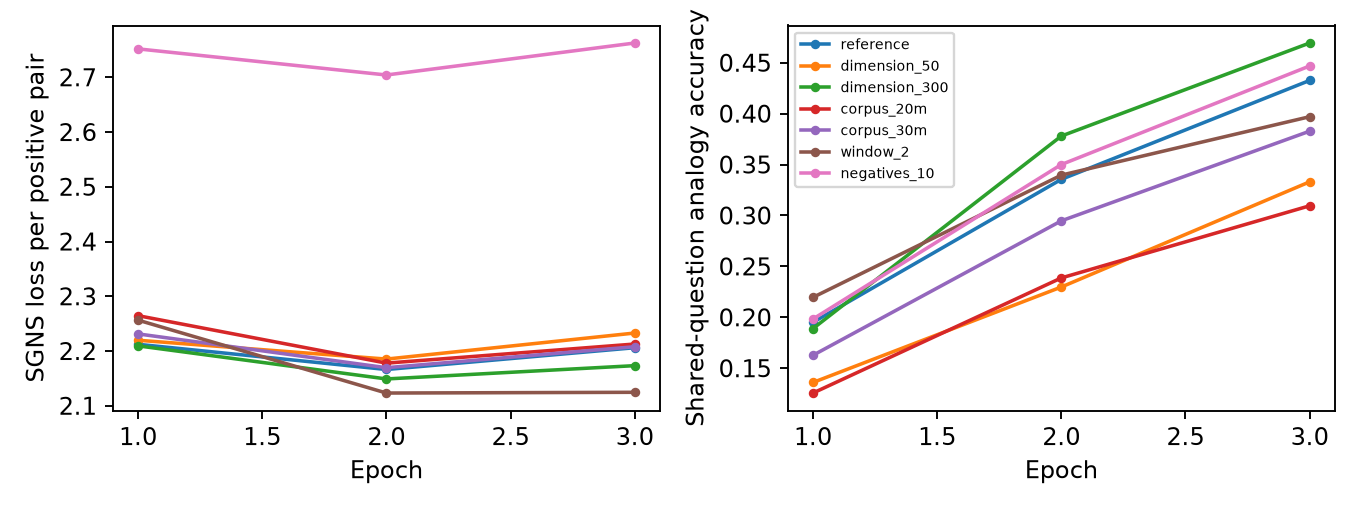

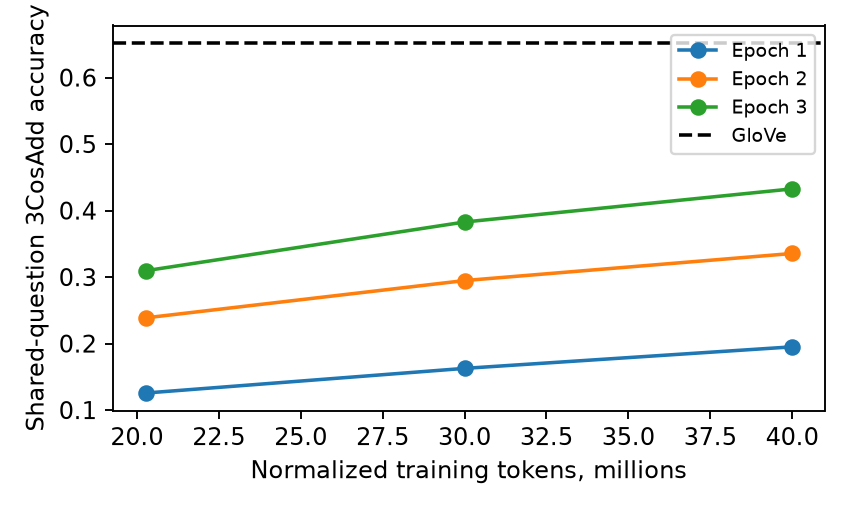

In [9]:
iterations = pd.DataFrame(iteration_rows())
display(iterations)
display(pd.Series(load_json(RESULTS / 'best_sgns.json')))
display(Image(filename=str(FIGURES / 'embedding_training.png')))
display(Image(filename=str(FIGURES / 'corpus_size.png')))

### Five neighbors for fixed control words at every epoch

These outputs diagnose semantic changes without affecting the prespecified selection metric.

In [10]:
neighbor_rows = []
for config in CONFIGURATIONS:
    history = load_json(RESULTS / f'sgns_{config.name}.json')
    for epoch in history['epochs']:
        for word, values in epoch['neighbors'].items():
            neighbor_rows.append({'model': config.name, 'epoch': epoch['epoch'], 'word': word, 'top5': values})
gensim_history = load_json(RESULTS / 'gensim.json')
for epoch in gensim_history['epochs']:
    for word, values in epoch['neighbors'].items():
        neighbor_rows.append({'model': 'gensim', 'epoch': epoch['epoch'], 'word': word, 'top5': values})
display(HTML(pd.DataFrame(neighbor_rows).to_html(index=False)))
display(pd.DataFrame([{k: v for k, v in epoch.items() if k not in ('neighbors', 'analogies')} for epoch in gensim_history['epochs']]))

model,epoch,word,top5
reference,1,king,"[[edward, 0.7534087896347046], [dukedom, 0.7522999048233032], [sweyn, 0.7522977590560913], [cnut, 0.7522657513618469], [knighted, 0.7510250806808472]]"
reference,1,france,"[[italy, 0.8226928114891052], [belgium, 0.809345543384552], [germany, 0.8044596910476685], [netherlands, 0.7840253114700317], [spain, 0.779522180557251]]"
reference,1,computer,"[[computers, 0.8380500674247742], [handheld, 0.798723578453064], [spacewar, 0.7832579016685486], [workstation, 0.7760751247406006], [desktop, 0.774895191192627]]"
reference,1,good,"[[decent, 0.7874531745910645], [dependable, 0.7324485182762146], [horrendous, 0.726429283618927], [excellent, 0.7139718532562256], [bad, 0.7100296020507812]]"
reference,1,january,"[[november, 0.9092226624488831], [december, 0.8831420540809631], [june, 0.881173312664032], [july, 0.8659535646438599], [october, 0.8572725057601929]]"
reference,1,run,"[[runs, 0.7152366042137146], [unearned, 0.7145450711250305], [yarder, 0.7103699445724487], [edging, 0.7096237540245056], [trailed, 0.7086942791938782]]"
reference,2,king,"[[dukedom, 0.7666043639183044], [balliol, 0.7519508600234985], [1286, 0.7507950663566589], [1413, 0.7492152452468872], [fitzempress, 0.7458774447441101]]"
reference,2,france,"[[belgium, 0.8247720003128052], [spain, 0.8064473867416382], [netherlands, 0.794064998626709], [italy, 0.7886845469474792], [germany, 0.7863882780075073]]"
reference,2,computer,"[[computers, 0.8277214765548706], [desktop, 0.7851743698120117], [programmable, 0.7776669859886169], [software, 0.770504355430603], [spacewar, 0.7695143222808838]]"
reference,2,good,"[[decent, 0.7659507989883423], [bad, 0.7375093698501587], [excellent, 0.7172853350639343], [poor, 0.6925989389419556], [dependable, 0.6785122752189636]]"


,epoch,loss_total,effective_words,raw_words,training_seconds,gpu_peak_bytes,wordsim
0,1,56449356.0,23470789,39275085,73.606934,None,"{'spearman': 0.5814563115048295, 'evaluated': 352, 'total': 353, 'coverage': 0.9971671388101983}"
1,2,55456608.0,23471921,39275085,68.094344,None,"{'spearman': 0.6501139348899896, 'evaluated': 352, 'total': 353, 'coverage': 0.9971671388101983}"
2,3,55259500.0,23475963,39275085,68.208001,None,"{'spearman': 0.6803034400987804, 'evaluated': 352, 'total': 353, 'coverage': 0.9971671388101983}"


## 5. Vector arithmetic

3CosAdd uses normalized source vectors, normalizes the resulting query and excludes its three words. The custom results are checked against gensim. Individual ranks use the complete original model vocabulary.

In [11]:
print(inspect.getsource(analogia))
if RUN_TRAINING:
    arithmetic()
arithmetic_results = load_json(RESULTS / 'arithmetic.json')

def analogia(vectors, a, b, c, k=5, exclude=True):
    if any(word not in vectors for word in (a, b, c)):
        return []
    words = vectors.index_to_key
    matrix = normalized_tensor(vectors, words)
    indices = [vectors.key_to_index[word] for word in (a, b, c)]
    scores = analogy_scores(matrix, *indices)
    if exclude:
        scores[indices] = -torch.inf
    values, positions = torch.topk(scores, min(k, len(words) - 3 if exclude else len(words)))
    return [(words[position], float(value)) for position, value in zip(positions.tolist(), values.tolist())]



In [12]:
for name, model in arithmetic_results['models'].items():
    print(name)
    display(HTML(pd.DataFrame(model['individual']).to_html(index=False)))
print('Shared vocabulary:', len(arithmetic_results['shared_words']))
display(pd.DataFrame(category_rows()))
display(pd.DataFrame({name: {'coverage': model['analogies']['coverage'], 'evaluated': model['analogies']['evaluated'], 'total': model['analogies']['total'], '3CosAdd': model['analogies']['3CosAdd']['total'], '3CosMul': model['analogies']['3CosMul']['total']} for name, model in arithmetic_results['models'].items()}).T)

sgns


type,a,b,c,expected,answer_cosine,without_exclusion,answer_rank,top5,gensim_match
gender,man,woman,king,queen,0.578209,"[[king, 0.7467398643493652], [queen, 0.5782085657119751], [consort, 0.4973185360431671], [coronation, 0.4900137186050415], [anointed, 0.4795311689376831]]",1,"[[queen, 0.5782085657119751], [consort, 0.4973185360431671], [coronation, 0.4900137186050415], [anointed, 0.4795311689376831], [princess, 0.4772665202617645]]",True
gender,boy,girl,father,mother,0.573619,"[[father, 0.7190023064613342], [mother, 0.5736187100410461], [husband, 0.5703352689743042], [girl, 0.565230131149292], [stepfather, 0.5496365427970886]]",1,"[[mother, 0.5736187100410461], [husband, 0.5703352689743042], [stepfather, 0.5496365427970886], [grandmother, 0.5438432693481445], [wife, 0.5386998057365417]]",True
gender,brother,sister,uncle,aunt,0.548785,"[[sister, 0.7133469581604004], [uncle, 0.6452164053916931], [aunt, 0.5487846732139587], [sisters, 0.5390694737434387], [paternal, 0.507291316986084]]",1,"[[aunt, 0.5487846732139587], [sisters, 0.5390694737434387], [paternal, 0.507291316986084], [dursley, 0.5030678510665894], [nieces, 0.4971765875816345]]",True
capital,france,paris,italy,rome,0.494382,"[[paris, 0.7157306671142578], [italy, 0.6635382771492004], [munich, 0.5462980270385742], [bologna, 0.5446901321411133], [milan, 0.5440110564231873]]",22,"[[munich, 0.5462980270385742], [bologna, 0.5446901321411133], [milan, 0.5440110564231873], [sorbonne, 0.5351899862289429], [istanbul, 0.5312907099723816]]",True
capital,germany,berlin,spain,madrid,0.572586,"[[spain, 0.6149707436561584], [berlin, 0.6011092066764832], [madrid, 0.5725861191749573], [seville, 0.5525795221328735], [pamplona, 0.5479158163070679]]",1,"[[madrid, 0.5725861191749573], [seville, 0.5525795221328735], [pamplona, 0.5479158163070679], [zaragoza, 0.5139471888542175], [toulouse, 0.4952247440814972]]",True
capital,japan,tokyo,china,beijing,0.585667,"[[china, 0.7021416425704956], [tokyo, 0.6318531632423401], [beijing, 0.5856667757034302], [shanghai, 0.579692542552948], [guangzhou, 0.5423948168754578]]",1,"[[beijing, 0.5856667757034302], [shanghai, 0.579692542552948], [guangzhou, 0.5423948168754578], [nanjing, 0.5341676473617554], [bangkok, 0.5294724106788635]]",True
nationality,france,french,germany,german,0.755412,"[[german, 0.7554119229316711], [french, 0.6737838387489319], [germany, 0.6594441533088684], [austrian, 0.6369832158088684], [dutch, 0.5683242678642273]]",1,"[[german, 0.7554119229316711], [austrian, 0.6369832158088684], [dutch, 0.5683242678642273], [swedish, 0.5575119853019714], [finnish, 0.5369076728820801]]",True
nationality,italy,italian,spain,spanish,0.683487,"[[italian, 0.7326899170875549], [spanish, 0.6834868788719177], [spain, 0.6272121667861938], [portuguese, 0.5425851941108704], [french, 0.5235616564750671]]",1,"[[spanish, 0.6834868788719177], [portuguese, 0.5425851941108704], [french, 0.5235616564750671], [espa, 0.50596684217453], [franco, 0.5032994747161865]]",True
nationality,japan,japanese,china,chinese,0.707380,"[[chinese, 0.7073796391487122], [china, 0.6943955421447754], [japanese, 0.6109254360198975], [sino, 0.5563486814498901], [qing, 0.5191317200660706]]",1,"[[chinese, 0.7073796391487122], [sino, 0.5563486814498901], [qing, 0.5191317200660706], [ming, 0.5120378732681274], [han, 0.5105486512184143]]",True
comparative,good,better,bad,worse,0.540100,"[[better, 0.6776004433631897], [bad, 0.5864714980125427], [worse, 0.5400999784469604], [ridding, 0.4135292172431946], [hassle, 0.4065898358821869]]",1,"[[worse, 0.5400999784469604], [ridding, 0.4135292172431946], [hassle, 0.4065898358821869], [bigger, 0.4035790264606476], [sexier, 0.4035700559616089]]",True


gensim


type,a,b,c,expected,answer_cosine,without_exclusion,answer_rank,top5,gensim_match
gender,man,woman,king,queen,0.554817,"[[king, 0.717811644077301], [queen, 0.5548174977302551], [anointed, 0.5048348903656006], [electress, 0.5027904510498047], [consort, 0.5007743835449219]]",1,"[[queen, 0.5548174977302551], [anointed, 0.5048348903656006], [electress, 0.5027904510498047], [consort, 0.5007743835449219], [lfgifu, 0.4864686131477356]]",True
gender,boy,girl,father,mother,0.598947,"[[father, 0.7237001657485962], [husband, 0.6091484427452087], [mother, 0.5989465713500977], [girl, 0.5674364566802979], [stepfather, 0.5542516112327576]]",2,"[[husband, 0.6091484427452087], [mother, 0.5989465713500977], [stepfather, 0.5542516112327576], [daughter, 0.553303599357605], [grandmother, 0.5495327115058899]]",True
gender,brother,sister,uncle,aunt,0.518598,"[[sister, 0.7133334875106812], [uncle, 0.6545212864875793], [clemm, 0.5261493921279907], [dursley, 0.5257963538169861], [aunt, 0.5185983777046204]]",3,"[[clemm, 0.5261493921279907], [dursley, 0.5257963538169861], [aunt, 0.5185983777046204], [nieces, 0.5118827223777771], [sisters, 0.5117561221122742]]",True
capital,france,paris,italy,rome,0.489332,"[[paris, 0.726260781288147], [italy, 0.6507281064987183], [milan, 0.5408775806427002], [padua, 0.5305430889129639], [berlin, 0.5231269001960754]]",11,"[[milan, 0.5408775806427002], [padua, 0.5305430889129639], [berlin, 0.5231269001960754], [munich, 0.5201972126960754], [bologna, 0.5119854211807251]]",True
capital,germany,berlin,spain,madrid,0.537155,"[[spain, 0.6161792278289795], [berlin, 0.6096922159194946], [seville, 0.593131959438324], [pamplona, 0.5523905754089355], [madrid, 0.5371547937393188]]",3,"[[seville, 0.593131959438324], [pamplona, 0.5523905754089355], [madrid, 0.5371547937393188], [teatro, 0.5228091478347778], [toulouse, 0.5226708054542542]]",True
capital,japan,tokyo,china,beijing,0.577275,"[[china, 0.7124616503715515], [tokyo, 0.6288357973098755], [beijing, 0.5772750377655029], [shanghai, 0.5560320615768433], [guangzhou, 0.550428569316864]]",1,"[[beijing, 0.5772750377655029], [shanghai, 0.5560320615768433], [guangzhou, 0.550428569316864], [tianjin, 0.525846540927887], [taipei, 0.5196587443351746]]",True
nationality,france,french,germany,german,0.740952,"[[german, 0.740951657295227], [french, 0.6651369333267212], [germany, 0.6625823974609375], [austrian, 0.609345555305481], [dutch, 0.5855914354324341]]",1,"[[german, 0.740951657295227], [austrian, 0.609345555305481], [dutch, 0.5855914354324341], [swedish, 0.5580652952194214], [danish, 0.5392084717750549]]",True
nationality,italy,italian,spain,spanish,0.685242,"[[italian, 0.7121070623397827], [spanish, 0.6852419376373291], [spain, 0.655156135559082], [portuguese, 0.5494088530540466], [french, 0.5376726984977722]]",1,"[[spanish, 0.6852419376373291], [portuguese, 0.5494088530540466], [french, 0.5376726984977722], [catalan, 0.5280323028564453], [espa, 0.5130988955497742]]",True
nationality,japan,japanese,china,chinese,0.698861,"[[chinese, 0.6988605856895447], [china, 0.6969215273857117], [japanese, 0.610848605632782], [tang, 0.5131171345710754], [malay, 0.4881104528903961]]",1,"[[chinese, 0.6988605856895447], [tang, 0.5131171345710754], [malay, 0.4881104528903961], [han, 0.4874061942100525], [sino, 0.48284438252449036]]",True
comparative,good,better,bad,worse,0.506933,"[[better, 0.6837577223777771], [bad, 0.6108008027076721], [worse, 0.506933331489563], [bigger, 0.4306880533695221], [than, 0.4112146496772766]]",1,"[[worse, 0.506933331489563], [bigger, 0.4306880533695221], [than, 0.4112146496772766], [escapology, 0.4109220504760742], [deadlier, 0.4082777798175812]]",True


glove


type,a,b,c,expected,answer_cosine,without_exclusion,answer_rank,top5,gensim_match
gender,man,woman,king,queen,0.769854,"[[king, 0.8360679149627686], [queen, 0.7698541283607483], [monarch, 0.6843381524085999], [throne, 0.6755735874176025], [daughter, 0.6594557762145996]]",1,"[[queen, 0.7698541283607483], [monarch, 0.6843381524085999], [throne, 0.6755735874176025], [daughter, 0.6594557762145996], [princess, 0.6520534157752991]]",True
gender,boy,girl,father,mother,0.901878,"[[father, 0.9181809425354004], [mother, 0.9018783569335938], [wife, 0.8842572569847107], [daughter, 0.8841628432273865], [husband, 0.856052815914154]]",1,"[[mother, 0.9018783569335938], [wife, 0.8842572569847107], [daughter, 0.8841628432273865], [husband, 0.856052815914154], [sister, 0.8180203437805176]]",True
gender,brother,sister,uncle,aunt,0.864503,"[[sister, 0.8944156169891357], [aunt, 0.8645027279853821], [grandmother, 0.7999028563499451], [mother, 0.7979602217674255], [daughter, 0.777729332447052]]",1,"[[aunt, 0.8645027279853821], [grandmother, 0.7999028563499451], [mother, 0.7979602217674255], [daughter, 0.777729332447052], [niece, 0.7675268054008484]]",True
capital,france,paris,italy,rome,0.818955,"[[rome, 0.8189547061920166], [italy, 0.7528195381164551], [milan, 0.7376196384429932], [paris, 0.7215927243232727], [naples, 0.7117615938186646]]",1,"[[rome, 0.8189547061920166], [milan, 0.7376196384429932], [naples, 0.7117615938186646], [venice, 0.7015421986579895], [turin, 0.6995178461074829]]",True
capital,germany,berlin,spain,madrid,0.780341,"[[madrid, 0.7803410291671753], [spain, 0.7255094051361084], [barcelona, 0.6701419353485107], [paris, 0.6608973145484924], [venice, 0.6589864492416382]]",1,"[[madrid, 0.7803410291671753], [barcelona, 0.6701419353485107], [paris, 0.6608973145484924], [venice, 0.6589864492416382], [rome, 0.6561428904533386]]",True
capital,japan,tokyo,china,beijing,0.832127,"[[beijing, 0.8321267366409302], [shanghai, 0.8276094198226929], [taipei, 0.7884564995765686], [seoul, 0.757804811000824], [china, 0.7558729648590088]]",1,"[[beijing, 0.8321267366409302], [shanghai, 0.8276094198226929], [taipei, 0.7884564995765686], [seoul, 0.757804811000824], [hong, 0.7376784086227417]]",True
nationality,france,french,germany,german,0.959673,"[[german, 0.959672749042511], [germany, 0.7963167428970337], [austrian, 0.7773436903953552], [swiss, 0.7663083672523499], [swedish, 0.7341678738594055]]",1,"[[german, 0.959672749042511], [austrian, 0.7773436903953552], [swiss, 0.7663083672523499], [swedish, 0.7341678738594055], [polish, 0.7259849905967712]]",True
nationality,italy,italian,spain,spanish,0.922745,"[[spanish, 0.9227451086044312], [italian, 0.7843459248542786], [spain, 0.76735520362854], [french, 0.7532532215118408], [argentine, 0.72343510389328]]",1,"[[spanish, 0.9227451086044312], [french, 0.7532532215118408], [argentine, 0.72343510389328], [portuguese, 0.7121981382369995], [mexican, 0.707392156124115]]",True
nationality,japan,japanese,china,chinese,0.953373,"[[chinese, 0.9533727169036865], [china, 0.8064448833465576], [taiwanese, 0.7891280055046082], [japanese, 0.745428204536438], [mainland, 0.7397264838218689]]",1,"[[chinese, 0.9533727169036865], [taiwanese, 0.7891280055046082], [mainland, 0.7397264838218689], [vietnamese, 0.7387635707855225], [korean, 0.7252402305603027]]",True
comparative,good,better,bad,worse,0.844293,"[[bad, 0.8963203430175781], [worse, 0.8442932367324829], [better, 0.776608943939209], [too, 0.7491366267204285], [even, 0.7305890917778015]]",1,"[[worse, 0.8442932367324829], [too, 0.7491366267204285], [even, 0.7305890917778015], [getting, 0.7304457426071167], [because, 0.7298995852470398]]",True


Shared vocabulary: 30000


,category,evaluated,total,S-Add,S-Mul,G-Add,G-Mul,V-Add,V-Mul
0,capital-common-countries,420,506,0.559524,0.571429,0.576190,0.585714,0.933333,0.916667
1,capital-world,1166,4524,0.399657,0.391081,0.381647,0.380789,0.895369,0.866209
2,currency,108,866,0.027778,0.037037,0.009259,0.027778,0.046296,0.037037
3,city-in-state,1811,2467,0.308117,0.301491,0.292104,0.287686,0.297626,0.260629
4,family,342,506,0.669591,0.634503,0.695906,0.681287,0.883041,0.874269
5,gram1-adjective-to-adverb,812,992,0.151478,0.131773,0.147783,0.134236,0.278325,0.279557
6,gram2-opposite,306,812,0.189542,0.147059,0.169935,0.130719,0.281046,0.245098
7,gram3-comparative,1332,1332,0.632883,0.634384,0.621622,0.617117,0.803303,0.780030
8,gram4-superlative,702,1122,0.330484,0.357550,0.317664,0.363248,0.612536,0.618234
9,gram5-present-participle,870,1056,0.439080,0.419540,0.439080,0.428736,0.731034,0.720690


,coverage,evaluated,total,3CosAdd,3CosMul
sgns,0.630475,12322.0,19544.0,0.469404,0.464292
gensim,0.630475,12322.0,19544.0,0.470459,0.468025
glove,0.630475,12322.0,19544.0,0.652005,0.632852


### Parallelism and the missing section 5.3

Independent raw difference vectors from the same relationship type are compared by cosine. Pairs sharing words are excluded. Without query exclusion, a high-ranking query word demonstrates why vector arithmetic should not be interpreted as exact equality.

In [13]:
print(inspect.getsource(parallelism))
for name, model in arithmetic_results['models'].items():
    print(name, model['parallelism']['mean_cosine'], model['parallelism']['comparisons'])
    display(pd.DataFrame(model['parallelism']['categories']).T)

def parallelism(vectors):
    pairs = defaultdict(list)
    for category, a, b, c, d in OWN_ANALOGIES:
        for pair in ((a, b), (c, d)):
            if pair not in pairs[category] and all(word in vectors for word in pair):
                pairs[category].append(pair)
    results = {}
    all_values = []
    for category, examples in pairs.items():
        values = []
        for i, (a, b) in enumerate(examples):
            for c, d in examples[i + 1:]:
                if len({a, b, c, d}) != 4:
                    continue
                first, second = vectors[b] - vectors[a], vectors[d] - vectors[c]
                denominator = np.linalg.norm(first) * np.linalg.norm(second)
                if denominator > 0:
                    values.append(float(first @ second / denominator))
        results[category] = {
            "comparisons": len(values),
            "mean_cosine": float(np.mean(values)) if values else None,
            "word_pairs": examples,
        }
        all_va

,comparisons,mean_cosine,word_pairs
gender,15,0.237118,"[[man, woman], [king, queen], [boy, girl], [father, mother], [brother, sister], [uncle, aunt]]"
capital,15,0.341197,"[[france, paris], [italy, rome], [germany, berlin], [spain, madrid], [japan, tokyo], [china, beijing]]"
nationality,15,0.516372,"[[france, french], [germany, german], [italy, italian], [spain, spanish], [japan, japanese], [china, chinese]]"
comparative,15,0.337575,"[[good, better], [bad, worse], [small, smaller], [large, larger], [fast, faster], [slow, slower]]"
past-tense,15,0.228113,"[[walk, walked], [play, played], [go, went], [run, ran], [see, saw], [eat, ate]]"
plural,15,0.172258,"[[dog, dogs], [cat, cats], [car, cars], [book, books], [child, children], [man, men]]"


gensim 0.29717714761694275 90


,comparisons,mean_cosine,word_pairs
gender,15,0.218156,"[[man, woman], [king, queen], [boy, girl], [father, mother], [brother, sister], [uncle, aunt]]"
capital,15,0.342395,"[[france, paris], [italy, rome], [germany, berlin], [spain, madrid], [japan, tokyo], [china, beijing]]"
nationality,15,0.51541,"[[france, french], [germany, german], [italy, italian], [spain, spanish], [japan, japanese], [china, chinese]]"
comparative,15,0.319345,"[[good, better], [bad, worse], [small, smaller], [large, larger], [fast, faster], [slow, slower]]"
past-tense,15,0.211202,"[[walk, walked], [play, played], [go, went], [run, ran], [see, saw], [eat, ate]]"
plural,15,0.176555,"[[dog, dogs], [cat, cats], [car, cars], [book, books], [child, children], [man, men]]"


glove 0.5909412526422076 90


,comparisons,mean_cosine,word_pairs
gender,15,0.612427,"[[man, woman], [king, queen], [boy, girl], [father, mother], [brother, sister], [uncle, aunt]]"
capital,15,0.641156,"[[france, paris], [italy, rome], [germany, berlin], [spain, madrid], [japan, tokyo], [china, beijing]]"
nationality,15,0.841043,"[[france, french], [germany, german], [italy, italian], [spain, spanish], [japan, japanese], [china, chinese]]"
comparative,15,0.467556,"[[good, better], [bad, worse], [small, smaller], [large, larger], [fast, faster], [slow, slower]]"
past-tense,15,0.527399,"[[walk, walked], [play, played], [go, went], [run, ran], [see, saw], [eat, ate]]"
plural,15,0.456067,"[[dog, dogs], [cat, cats], [car, cars], [book, books], [child, children], [man, men]]"


### Thematic t-SNE

Five groups each contribute 100 nonoverlapping words from anchor neighborhoods. Such selection favors visible clustering; this visualization is exploratory, not independent evidence of semantic separation.

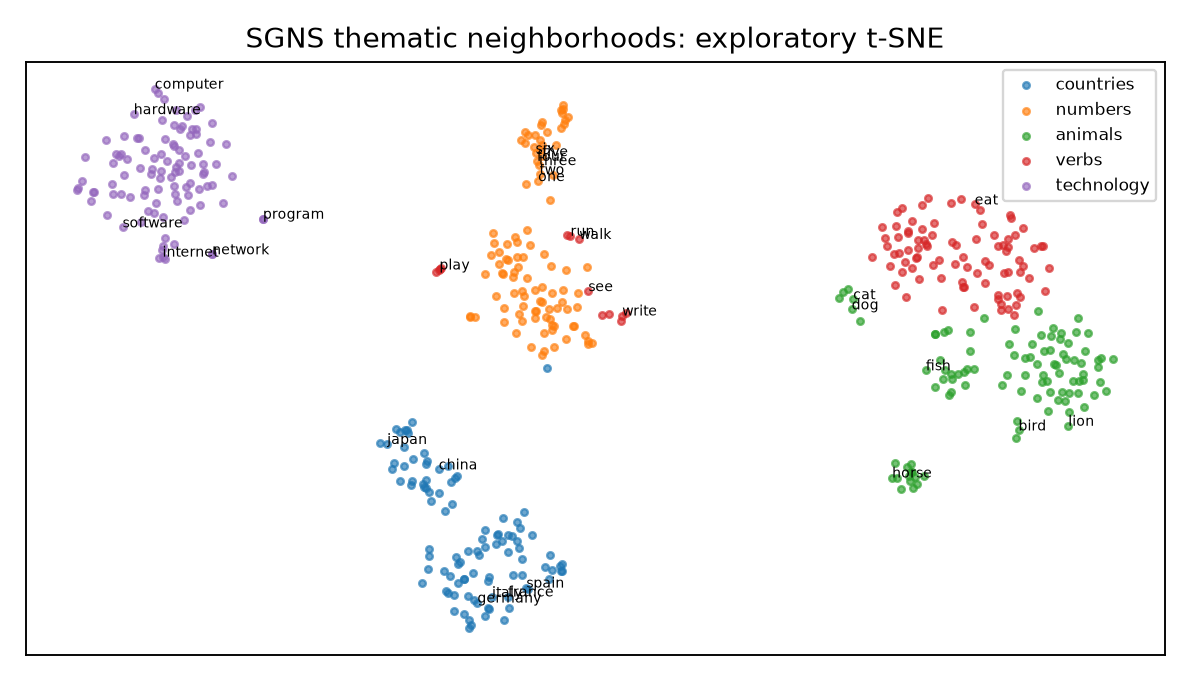

,anchors,words
countries,"[france, germany, italy, spain, japan, china]","[france, spain, italy, germany, japan, china, portugal, austria, belgium, netherlands, poland, taiwan, hungary, sweden, czecho..."
numbers,"[one, two, three, four, five, six]","[one, two, three, five, four, six, eight, seven, nine, twelve, ten, eighteen, eleven, fifteen, fourteen, thirteen, sixteen, tw..."
animals,"[dog, cat, horse, bird, fish, lion]","[dog, cat, horse, bird, fish, lion, horses, birds, thoroughbred, arabians, saddle, hatcheries, rockfowl, necked, salmon, stall..."
verbs,"[run, walk, eat, play, see, write]","[run, walk, eat, play, see, write, playing, consume, played, ate, eating, regurgitate, mayonnaise, regurgitated, crumbs, fatte..."
technology,"[computer, software, internet, hardware, network, program]","[computer, software, hardware, internet, network, program, programs, nvidia, sgi, chipset, console, interfaces, peripherals, m..."


In [14]:
display(Image(filename=str(FIGURES / 'tsne.png')))
display(pd.DataFrame(load_json(RESULTS / 'tsne.json')['groups']).T)

The observed technology group is compact. Countries separate into recognizable European and Asian neighborhoods, and numbers form subgroups. Animals and verbs overlap more, with some common verbs near the number region. The expected themes are visible but not perfectly separated; axes have no semantic meaning.

## 6. AG News end-to-end classification

The same tokenizer converts text to IDs, EmbeddingBag averages vectors, and an MLP predicts the class. A stratified 10% validation split is fixed. All TF-IDF fitting, tuning and epoch selection use training/validation only.

In [15]:
print(inspect.getsource(BagClassifier))
if RUN_TRAINING:
    classification()
selection = load_json(RESULTS / 'classification_selection.json')
display(pd.Series(selection['split']))
display(pd.DataFrame(validation_rows()))

class BagClassifier(nn.Module):
    def __init__(self, weights, freeze=False):
        super().__init__()
        self.embedding = nn.EmbeddingBag.from_pretrained(
            torch.as_tensor(weights, dtype=torch.float32),
            freeze=freeze, mode="mean", padding_idx=0, include_last_offset=True,
        )
        self.mlp = nn.Sequential(
            nn.Linear(weights.shape[1], 128), nn.ReLU(), nn.Dropout(0.2), nn.Linear(128, 4),
        )

    def forward(self, ids, offsets):
        return self.mlp(self.embedding(ids, offsets))



dataset_fingerprint                                                        2bc1e2be15d7f2ee
split_hash                 36399bf948a0dffb4e2addbeab6801867597d9aea3c6f935b48db79bdc5ea0bb
training_documents                                                                   108000
validation_documents                                                                  12000
training_class_counts                                          [27000, 27000, 27000, 27000]
validation_class_counts                                            [3000, 3000, 3000, 3000]
seed                                                                                  23556
dtype: object

,model,variant,accuracy,precision_macro,recall_macro,f1_macro,parameters,trainable,seconds
0,tfidf,logistic,0.921250,0.921411,0.921250,0.921060,400004,400004,39.602260
1,random,trainable,0.919833,0.919815,0.919833,0.919751,19638644,19638644,24.104708
2,sgns,frozen,0.895000,0.896345,0.895000,0.894835,24065444,39044,14.582575
3,sgns,finetuned,0.916000,0.916839,0.916000,0.915970,24065444,24065444,22.534892
4,gensim,frozen,0.891917,0.892942,0.891917,0.891926,24065444,39044,15.174326
5,gensim,finetuned,0.915917,0.916774,0.915917,0.915879,24065444,24065444,23.540456
6,glove,frozen,0.903167,0.903824,0.903167,0.902913,40013544,13444,14.443757
7,glove,finetuned,0.920500,0.920538,0.920500,0.920353,40013544,40013544,69.850169


,initialization,split,unknown_tokens,total_tokens,percent
0,random,train,0,4261825,0.000000
1,random,validation,2917,472838,0.616913
2,sgns,train,155987,4261825,3.660099
3,sgns,validation,17229,472838,3.643743
4,gensim,train,155987,4261825,3.660099
5,gensim,validation,17229,472838,3.643743
6,glove,train,46272,4261825,1.085732
7,glove,validation,5180,472838,1.095513


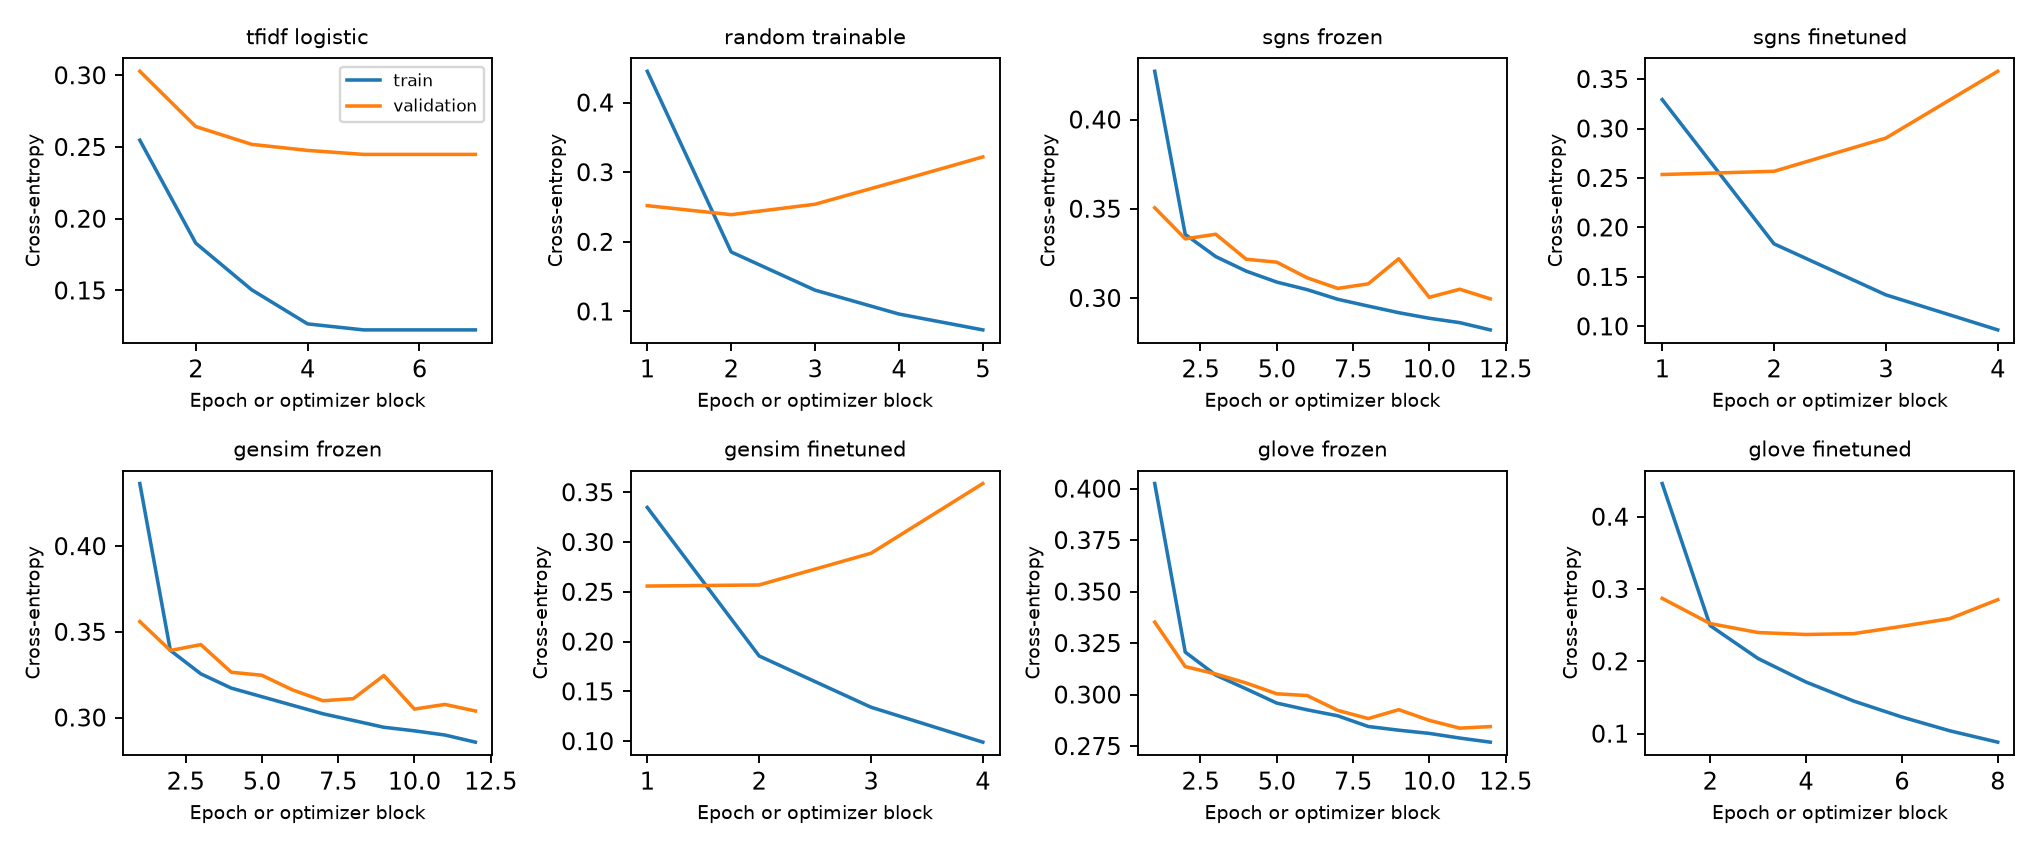

In [16]:
display(pd.DataFrame([{'initialization': name, 'split': split, **values} for name, splits in selection['oov'].items() for split, values in splits.items()]))
display(Image(filename=str(FIGURES / 'classification_training.png')))

### Training and validation curves for every classifier variant

Per-trial histories retain all four validation metrics, times and both losses. The figure above includes both frozen and fine-tuned full-data variants, random embeddings and TF-IDF.

In [17]:
trial_epochs = [{'model': row['key'], **epoch} for row in selection['trials'] for epoch in row['epochs']]
display(HTML(pd.DataFrame(trial_epochs).to_html(index=False)))
display(pd.DataFrame([{'key': key, 'variant': row.get('variant', 'logistic'), 'fraction': row['fraction'], **row['validation']} for key, row in selection['selected'].items()]))

model,epoch,training_loss,validation_loss,accuracy,precision_macro,recall_macro,f1_macro,seconds
random_trainable_f0.01_lr0.001,1,1.386135,1.383077,0.353250,0.427193,0.353250,0.233223,0.477342
random_trainable_f0.01_lr0.001,2,1.379123,1.378420,0.419167,0.445561,0.419167,0.342273,0.138847
random_trainable_f0.01_lr0.001,3,1.370142,1.370866,0.513667,0.431608,0.513667,0.440325,0.142039
random_trainable_f0.01_lr0.001,4,1.355410,1.358655,0.592333,0.688612,0.592333,0.533744,0.151894
random_trainable_f0.01_lr0.001,5,1.332068,1.339904,0.656750,0.723762,0.656750,0.637291,0.150355
random_trainable_f0.01_lr0.001,6,1.296616,1.311903,0.710583,0.750173,0.710583,0.704323,0.145582
random_trainable_f0.01_lr0.001,7,1.245192,1.272578,0.734833,0.764471,0.734833,0.727883,0.145038
random_trainable_f0.01_lr0.001,8,1.174298,1.219673,0.740000,0.769838,0.740000,0.728601,0.158257
random_trainable_f0.01_lr0.001,9,1.079372,1.152561,0.739583,0.772337,0.739583,0.727052,0.158550
random_trainable_f0.01_lr0.001,10,0.961317,1.072087,0.757917,0.782710,0.757917,0.748230,0.154569


,key,variant,fraction,accuracy,precision_macro,recall_macro,f1_macro
0,tfidf_f0.01,logistic,0.01,0.833167,0.832444,0.833167,0.832373
1,tfidf_f0.1,logistic,0.10,0.892000,0.891708,0.892000,0.891677
2,tfidf_f0.5,logistic,0.50,0.914500,0.914478,0.914500,0.914364
3,tfidf_f1,logistic,1.00,0.921250,0.921411,0.921250,0.921060
4,random_f0.01,trainable,0.01,0.829333,0.830454,0.829333,0.829547
5,random_f0.1,trainable,0.10,0.890917,0.890616,0.890917,0.890708
6,random_f0.5,trainable,0.50,0.913333,0.913630,0.913333,0.913234
7,random_f1,trainable,1.00,0.919833,0.919815,0.919833,0.919751
8,sgns_f0.01,finetuned,0.01,0.857833,0.857954,0.857833,0.857675
9,sgns_f0.1,finetuned,0.10,0.894583,0.894589,0.894583,0.894506


### Locked final evaluation

The final stage is opt-in, checks the selection hash, and caches each selected test result. SimLex-999 is evaluated only here for the original embeddings, not their classification-tuned copies.

,accuracy,precision_macro,recall_macro,f1_macro,selected_configuration,oov,confusion_matrix,fraction
tfidf_f0.01,0.8225,0.8213,0.8225,0.821479,baseline_f0.01,None,"[[1585, 105, 104, 106], [74, 1765, 25, 36], [123, 64, 1438, 275], [119, 95, 223, 1463]]",0.01
tfidf_f0.1,0.890395,0.889946,0.890395,0.890029,baseline_f0.1,None,"[[1685, 71, 85, 59], [38, 1833, 13, 16], [87, 30, 1592, 191], [68, 29, 146, 1657]]",0.1
tfidf_f0.5,0.915263,0.915226,0.915263,0.915172,baseline_f0.5,None,"[[1718, 55, 75, 52], [25, 1847, 16, 12], [63, 17, 1679, 141], [41, 18, 129, 1712]]",0.5
tfidf_f1,0.923421,0.923432,0.923421,0.923249,baseline_f1,None,"[[1732, 50, 66, 52], [13, 1866, 12, 9], [59, 17, 1675, 149], [38, 17, 100, 1745]]",1.0
random_f0.01,0.831053,0.831809,0.831053,0.831091,random_trainable_f0.01_lr0.003,"{'unknown_tokens': 1887, 'total_tokens': 298170, 'percent': 0.6328604487372975}","[[1616, 69, 128, 87], [113, 1702, 59, 26], [101, 32, 1544, 223], [126, 63, 257, 1454]]",0.01
random_f0.1,0.892368,0.891997,0.892368,0.892094,random_trainable_f0.1_lr0.001,"{'unknown_tokens': 1887, 'total_tokens': 298170, 'percent': 0.6328604487372975}","[[1702, 63, 81, 54], [46, 1829, 14, 11], [92, 19, 1592, 197], [69, 23, 149, 1659]]",0.1
random_f0.5,0.911579,0.911657,0.911579,0.911515,random_trainable_f0.5_lr0.003,"{'unknown_tokens': 1887, 'total_tokens': 298170, 'percent': 0.6328604487372975}","[[1710, 51, 78, 61], [24, 1848, 19, 9], [67, 9, 1656, 168], [47, 16, 123, 1714]]",0.5
random_f1,0.921842,0.921793,0.921842,0.921735,random_trainable_f1_lr0.001,"{'unknown_tokens': 1887, 'total_tokens': 298170, 'percent': 0.6328604487372975}","[[1730, 51, 75, 44], [17, 1866, 13, 4], [53, 12, 1708, 127], [54, 11, 133, 1702]]",1.0
sgns_f0.01,0.858421,0.858233,0.858421,0.857937,sgns_finetuned_f0.01_lr0.003,"{'unknown_tokens': 10917, 'total_tokens': 298170, 'percent': 3.661334138243284}","[[1699, 60, 93, 48], [88, 1776, 15, 21], [134, 28, 1507, 231], [110, 45, 203, 1542]]",0.01
sgns_f0.1,0.895921,0.895787,0.895921,0.895803,sgns_finetuned_f0.1_lr0.001,"{'unknown_tokens': 10917, 'total_tokens': 298170, 'percent': 3.661334138243284}","[[1696, 62, 93, 49], [35, 1839, 15, 11], [81, 14, 1620, 185], [46, 22, 178, 1654]]",0.1


,spearman,evaluated,total,coverage
sgns,0.330029,993.0,999.0,0.993994
gensim,0.336973,993.0,999.0,0.993994
glove,0.297550,999.0,999.0,1.000000


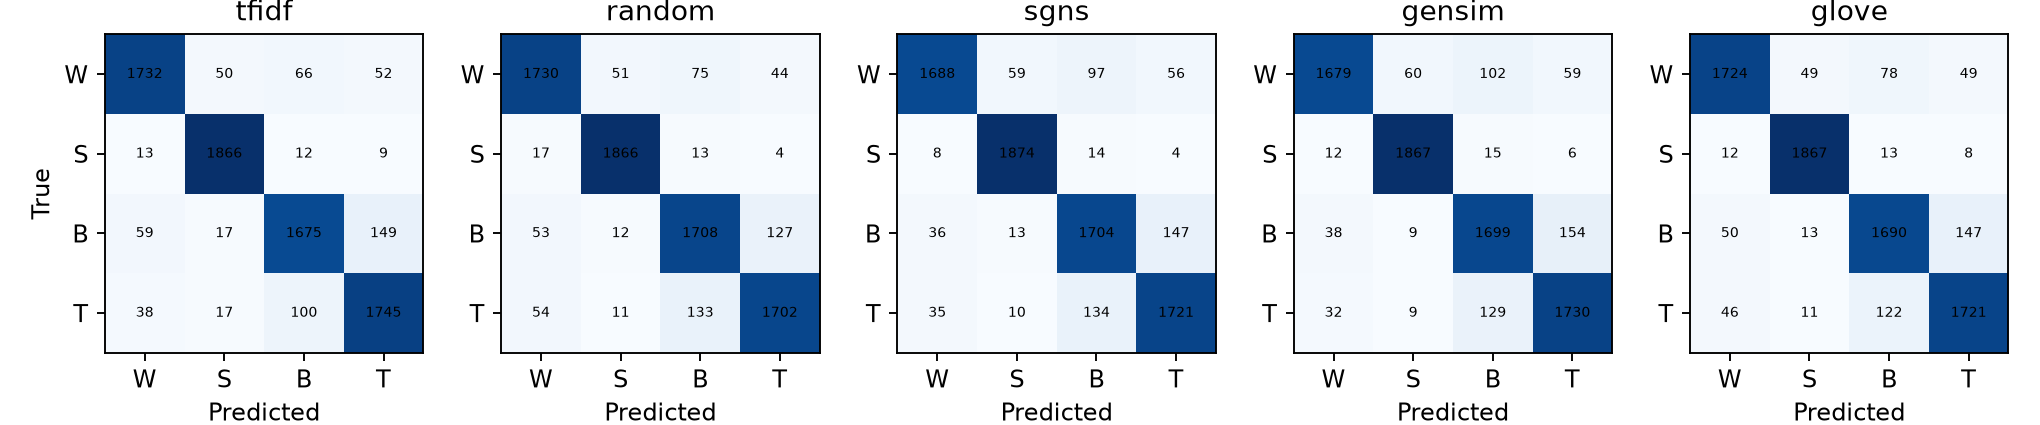

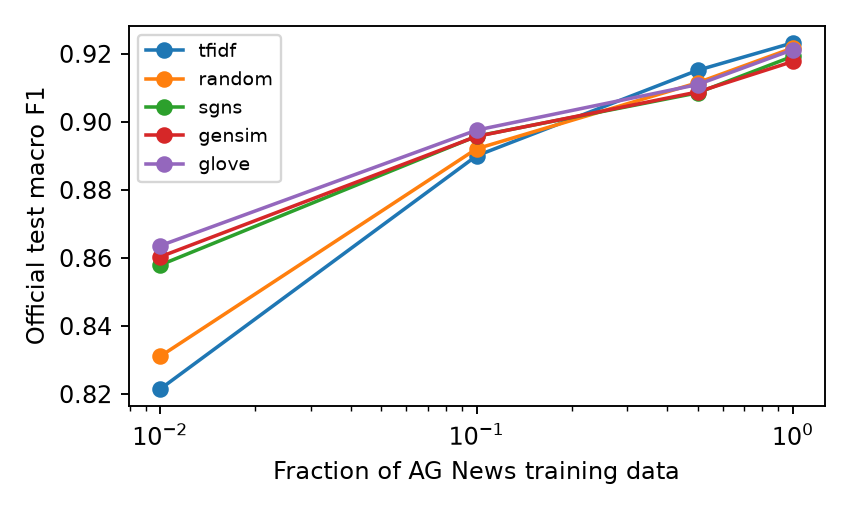

In [18]:
if RUN_TRAINING:
    final_evaluation()
final = load_json(RESULTS / 'final_evaluation.json')
display(pd.DataFrame(final['models']).T)
display(pd.DataFrame(final['simlex']).T)
display(Image(filename=str(FIGURES / 'confusion_matrices.png')))
display(Image(filename=str(FIGURES / 'data_efficiency.png')))

## 7. Full comparison

The GloVe corpus and vocabulary come from the original release. Its exact 100D training time and CPU model are unavailable. Every metric includes its appropriate coverage denominator in the saved JSON.

In [19]:
comparison = pd.DataFrame(embedding_rows())
display(comparison)
print('Best original vectors:', ARTIFACTS / 'best_sgns.kv')

,model,corpus_tokens,vocabulary,dimension,training_seconds,hardware,add_semantic,add_syntactic,add_total,mul_semantic,mul_syntactic,mul_total,analogy_coverage,wordsim,wordsim_coverage,simlex,simlex_coverage,parallelism,ag_news_oov_percent,test_f1
0,sgns,40000011,80087,300,450.069026,NVIDIA GeForce RTX 4050 Laptop GPU,0.387575,0.506549,0.469404,0.380296,0.502419,0.464292,0.630475,0.680015,0.997167,0.330029,0.993994,0.305439,3.661334,0.919306
1,gensim,40000011,80087,300,209.909278,"CPU, four workers",0.378217,0.512330,0.470459,0.376137,0.509735,0.468025,0.630475,0.680303,0.997167,0.336973,0.993994,0.297177,3.661334,0.917762
2,glove,6000000000,400000,100,NaN,Original 100D release: exact CPU model and wall time not reported,0.593189,0.678702,0.652005,0.564076,0.664071,0.632852,0.630475,0.532735,1.000000,0.297550,1.000000,0.590941,1.044371,0.921235


Best original vectors: C:\Users\hdaniyyel\UVG\Ciclo 2\DeepLearning\Lab7\informe\artifacts\best_sgns.kv


## 8. Discussion and conclusions

The following report provides the numerical interpretation, including dimension, context, negatives, corpus size, arithmetic limitations and performance at 1% labeled data.

In [20]:
report = (ROOT / 'informe' / 'report.md').read_text(encoding='utf-8')
pages = report.split('\\newpage')
display(Markdown('### Dimensions, corpus size and loss\n\nThe selected model is' + pages[1].split('The selected model is')[1]))
display(Markdown('### Analogy strengths and limits\n\nThe strongest SGNS category is' + pages[2].split('The strongest SGNS category is')[1]))
display(Markdown('### Freezing, adaptation and labeled data\n\nVariant selections:' + pages[3].split('Variant selections:')[1]))
display(Markdown('### Direct comparison and limitations\n\nSGNS semantic/syntactic' + pages[4].split('SGNS semantic/syntactic')[1]))

### Dimensions, corpus size and loss

The selected model is **dimension_300, epoch 3**.
Selection uses only shared-question 3CosAdd accuracy then WordSim-353.
SimLex and AG News test are held out. Best analogy accuracy for dimensions
50/100/300 is 0.333/0.433/
0.469. For 20M/30M/40M tokens it is
0.310/0.383/0.433.
Window two yields 0.397; ten negatives yield 0.447.
These are descriptive single-seed comparisons, not statistical significance tests.
In the reference run, loss changes from 2.166 at epoch two to 2.206 at epoch three, while analogy accuracy changes from 0.335 to 0.433. A lower negative-sampling loss is not an unconditional
quality guarantee: the objective and benchmarks measure different properties.
Cross-negative-count losses also change their number of terms.



### Analogy strengths and limits

The strongest SGNS category is gram6-nationality-adjective at 0.838;
the weakest is currency at 0.028.
Query words can dominate without exclusion, and difference vectors are not
perfectly parallel. Consequently the familiar king−man+woman expression is
approximate retrieval, not equality. A 500-word thematic t-SNE is in the notebook:
technology and countries form recognizable groups, while verbs and animals
overlap more. Neighborhood-based theme selection itself favors visible grouping.



### Freezing, adaptation and labeled data

Variant selections: sgns: finetuned at 100%, finetuned at 1%; gensim: finetuned at 100%, finetuned at 1%; glove: finetuned at 100%, finetuned at 1%.
The highest full-data test F1 belongs to tfidf at 0.923.
The 1% experiment contains 1,080 training documents, with validation unchanged.
Fine-tuning wins validation selection at all four fractions; freezing reduces
trainable parameters but never gives the best F1 here. Pretrained vectors do
not beat TF-IDF or random vectors at full data, but all three improve over both
at 1%. The narrow full-data margins do not establish statistical superiority.



### Direct comparison and limitations

SGNS semantic/syntactic accuracy is 0.388/0.507. The overall GloVe minus SGNS gap is +0.183; gensim minus SGNS is +0.001. At epoch three, window 2 versus 5 changes semantic accuracy from 0.339 to 0.247 and syntactic accuracy from 0.475 to 0.465. Ten versus five negatives changes overall accuracy from 0.433 to 0.447.

The corpus-size experiment measures a within-SGNS scaling trend, not a causal
decomposition of the GloVe gap. GloVe differs in corpus composition, tokenization,
objective and training budget. Small windows reduce semantic accuracy more than
syntactic accuracy here, but do not improve absolute syntactic accuracy. More
negatives improve overall accuracy under the measured budget, not necessarily
every category. Gensim discrepancies remain consistent
with the documented optimization differences rather than proof that either
objective is implemented incorrectly. Single-seed results, approximate sentence
splitting and fixed vocabulary limit generalization.

**Sources:** Mikolov et al. 2013, arXiv:1310.4546; Pennington et al. 2014,
EMNLP, nlp.stanford.edu/pubs/glove.pdf; Stanford original GloVe release;
PyTorch Embedding/EmbeddingBag and gensim Word2Vec documentation.
Full links and API research are in `research.md` and the notebook.
Best original vectors: `informe/artifacts/best_sgns.kv`.
